# 09 · Presentation rendering — the dark theme

Notebooks `01`–`08` are the analytical record and keep their light figures. **This notebook is the
only place presentation assets are rendered.** It exists so that the deck and the video cannot drift
apart: both come from here, from the same numbers, in one pass.

**It invents nothing.** Every series is read back out of the five JSON files written by the plate
cells in `03`, `06`, `07` and `08`. No data is recomputed, so a number cannot change here without
having changed upstream first.

Two files come out per chart:

| Output | For | Contains |
|---|---|---|
| `figures/dark/<name>.png` | the deck, and as the animation reference | axes **and** data |
| `figures/remotion/<name>_plate.png` | Remotion | axes only, transparent, **no data** |

Because both are drawn by the same function, the animated version and the static version cannot
disagree about where a point sits.

**Labels live here.** Titles, axis labels and tick labels are declared in the `CHARTS` spec below
rather than read from the JSON, because the JSON carries geometry and series, not copy. That makes
this file the one place to audit wording — and the one place that has to be updated if a chart's
meaning changes upstream.

## Palette and setup

In [1]:
import json, pathlib, shutil
import numpy as np, matplotlib
import matplotlib.pyplot as plt, matplotlib.dates as mdates
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D

CWD  = pathlib.Path.cwd()
NB   = next((p for p in [CWD, CWD/"notebook", *CWD.parents] if (p/"figures").is_dir()), CWD)
FIG  = NB/"figures"; REM = FIG/"remotion"; DARK = FIG/"dark"
DARK.mkdir(exist_ok=True)

# MOTION.md, verbatim. The series colours are brightened: #2E86DE reads muddy on near-black.
BG, LIFT = "#0B0C10", "#14161C"
INK, SOFT, LINE = "#E8ECF2", "#8A94A6", "#39414E"
ACCENT, WARN, GOLD, DIM = "#4DA3FF", "#FF6B5E", "#F5A623", "#7FB2E5"

# Light hexes used upstream -> their dark-theme equivalent.
REMAP = {"#2E86DE": ACCENT, "#1B2430": INK,   "#E74C3C": WARN,
         "#F39C12": GOLD,   "#9BbFdE": DIM,   "#7FB2E5": DIM,
         "#4DA3FF": ACCENT, "#FF6B5E": WARN,  "#F5A623": GOLD}

def dark_rc():
    plt.rcParams.update({
        "text.color": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
        "axes.edgecolor": LINE, "grid.color": LINE, "font.size": 13,
        "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    })

def load(name):
    # 09 writes its plate JSON back to remotion/<name>.json, and for reach_over_time it
    # writes a FILTERED series list. So the first time a chart is seen, keep a pristine
    # copy of what the upstream notebook wrote and read from that copy afterwards.
    # Without this, a second run of 09 would be reading its own output and the three
    # channels dropped from the deck figure would exist nowhere until 03 was re-run.
    src, live = REM/f"{name}.source.json", REM/f"{name}.json"
    if not src.exists():
        shutil.copy(live, src)
    d = json.load(open(src))
    for s in d["series"]:
        s["color"] = REMAP.get(s.get("color", ""), s.get("color", ACCENT))
    return d

def decline_window(s, year, look=8):
    """Locate the fall the slide is about *from the data*, not by eye: the highest
    quarter inside `year`, then the lowest of the `look` quarters after it. Returning
    the dates and the drop means the band and its label can never disagree with the
    line, and re-running after a data refresh moves both together."""
    dates = [str(v)[:10] for v in s["x"]]
    xn, y = s["x_num"], s["y"]
    peak   = max((i for i, v in enumerate(dates) if v[:4] == str(year)), key=lambda i: y[i])
    trough = min(range(peak + 1, min(peak + 1 + look, len(y))), key=lambda i: y[i])
    drop   = y[trough] / y[peak] - 1
    return dict(x0=xn[peak], x1=xn[trough], date0=dates[peak], date1=dates[trough],
                y0=y[peak], y1=y[trough], quarters=trough - peak, drop=drop,
                label=f"\u2212{abs(drop) * 100:.0f}% in {trough - peak} quarters")

print("reading:", ", ".join(sorted(p.stem for p in REM.glob("*.json") if not p.name.endswith(".source.json"))))

reading: commercial_surface_left, commercial_surfaces, content_model_right, pace_vs_wording, positive_control, reach_over_time, stability


## The chart spec

One entry per chart: which JSON it reads, the copy, and any per-chart drawing choices. Everything
that differs between the five charts is declared here; the renderer below has no chart-specific
branches except on `kind`.

In [2]:
CHARTS = {
 "reach_over_time": dict(
     size=(11.6, 4.6),
     title="ShortCircuit \u2014 per-video reach, quarterly",   # the y label says "median views"
     ylabel="Median views per video",
     date_x=True,
     # ShortCircuit alone. The four-channel version made the comparison the subject and
     # the protagonist one line of four; the slide's job is the shape of ONE channel's
     # fall, and three extra lines cost more attention than they returned.
     only=["ShortCircuit"],
     # Recoloured from its four-channel gold to the accent blue: with the other channels
     # gone, gold no longer distinguishes anything, and accent is the primary series
     # everywhere else in the deck.
     recolor={"ShortCircuit": ACCENT},
     # Linear, from zero. On a log axis a 45% fall looks like a gentle slope; log existed
     # to fit four channels an order of magnitude apart into one frame, and with one
     # series that reason is gone. Zero baseline because the claim is about a proportion.
     yscale="linear", autoscale=True, y_from_zero=True, ytick_thousands=True,
     # Cut the last twelve months. View counts are cumulative, so uploads younger than a
     # year have not finished collecting them; the steep 2026 fall in the four-channel
     # version was that accrual, not a second decline, and it contradicted the slide it
     # was on. Every other measurement in this analysis is on a same-age basis, so this
     # chart was the one place the rule was not being applied.
     trim_days=365,
     legend=None,
     # No in-chart note and no legend: one line, named in the title.
     highlight=dict(year=2022),
 ),
 "commercial_surfaces": dict(
     size=(11.6, 4.6),
     title="Four commercial surfaces, six years, all at the ceiling",
     ylabel="Share of long-form uploads (%)",
     # Grouped bars, never stacked: the four surfaces are not mutually exclusive, so a
     # stack would sum to about 400%. The previous version of this slide was three
     # lines, one of which — what the old four-domain regex saw — fell to 21% while the
     # narration said the surface was full. A viewer not reading the caption saw the
     # screen contradict the sentence.
     bars=True, xticks_year=True, yticks=[0, 25, 50, 75, 100], ylim=(0, 104),
     # The legend goes ABOVE the axes. Bars that run from 0 to the ceiling leave no
     # interior space, so an inside legend lands on top of the data — which is what the
     # first render did. No in-chart note for the same reason; the 90.4% caveat is on
     # the slide footnote instead.
     legend="above", legend_cols=4,
 ),
 "positive_control": dict(
     size=(9.8, 4.6),
     title="94% against what?",
     ylabel="Channel named correctly (%)",
     # Three bars, two of them floors. The model bar is the only one in the accent
     # colour: the two baselines are what it has to clear, not things to celebrate.
     bars=True, yticks=[0, 25, 50, 75, 100], ylim=(0, 112), bar_labels=True,
     xtick_labels=["guess at random", "always the\nbiggest channel", "my model"],
     legend=None,
     # No in-chart note: the only free space is beside the tallest bar, which is where
     # the 94.2% label sits. The sample size and the 25%-by-construction point are on
     # the slide footnote instead.
 ),
 "hit_rate": dict(
     size=(9.8, 4.6),
     title="Same 76 picks, twice the hits",
     ylabel="Breakouts among the 76",
     # The AUC chart that used to be on this slide measured something the speaker notes
     # forbid saying out loud, so the audience heard 76-32-15 and read intervals. Two bars
     # of the same 76 picks, differing only in how they were chosen, is the spoken line.
     bars=True, yticks=[0, 10, 20, 30, 40], ylim=(0, 40), bar_labels=True,
     bar_label_fmt="%.0f",   # these are videos, not percentages
     xtick_labels=["76 picked at random", "my model's top 76"],
     legend=None,
 ),
 "content_model_right": dict(
     size=(9.8, 4.6),
     title="Only one channel clears chance decisively",
     xlabel="Test AUC, 95% bootstrap interval",
     note="Dashed line is chance. Trained before July 2024, tested after.",
     note_xy=(.985, .06), vline=0.5, invert_y=True,
 ),
 "pace_vs_wording": dict(
     size=(11.6, 4.6),
     # No internal title: the slide title is this exact sentence, and printing it
     # twice on one frame is the sort of thing nobody notices until it is on tape.
     title="",
     ylabel="Median rolling-baseline index",
     xtick_labels=["Q1  fewest", "Q2", "Q3", "Q4  most"],
     note="Pace  1.55×   ·   p < 0.0001\nWording  1.23×   ·   p = 0.0020",
     note_xy=(.985, .95), legend="lower left", hline=1.0,
 ),
 "stability": dict(
     size=(9.8, 5.4),
     title="24 configurations, 24 times the same direction",
     xlabel="Linus Tech Tips — median rolling-baseline index",
     ylabel="ShortCircuit — median rolling-baseline index",
     note="Every point below the diagonal means ShortCircuit\n"
          "underperforms the flagship on the same subject.",
     note_xy=(.03, .95), note_ha="left", legend="lower right", diagonal=True,
 ),
}
print(f"{len(CHARTS)} charts declared")

6 charts declared


## The renderer

`draw(name, with_data)` is called twice per chart. With data it writes the deck figure; without, the
transparent Remotion plate. Same axes, same limits, same labels — the only difference is whether the
marks are drawn, which is exactly the invariant the plate contract needs.

    reach_over_time: trimmed to 2025-06-30 (365d before the last upload quarter)


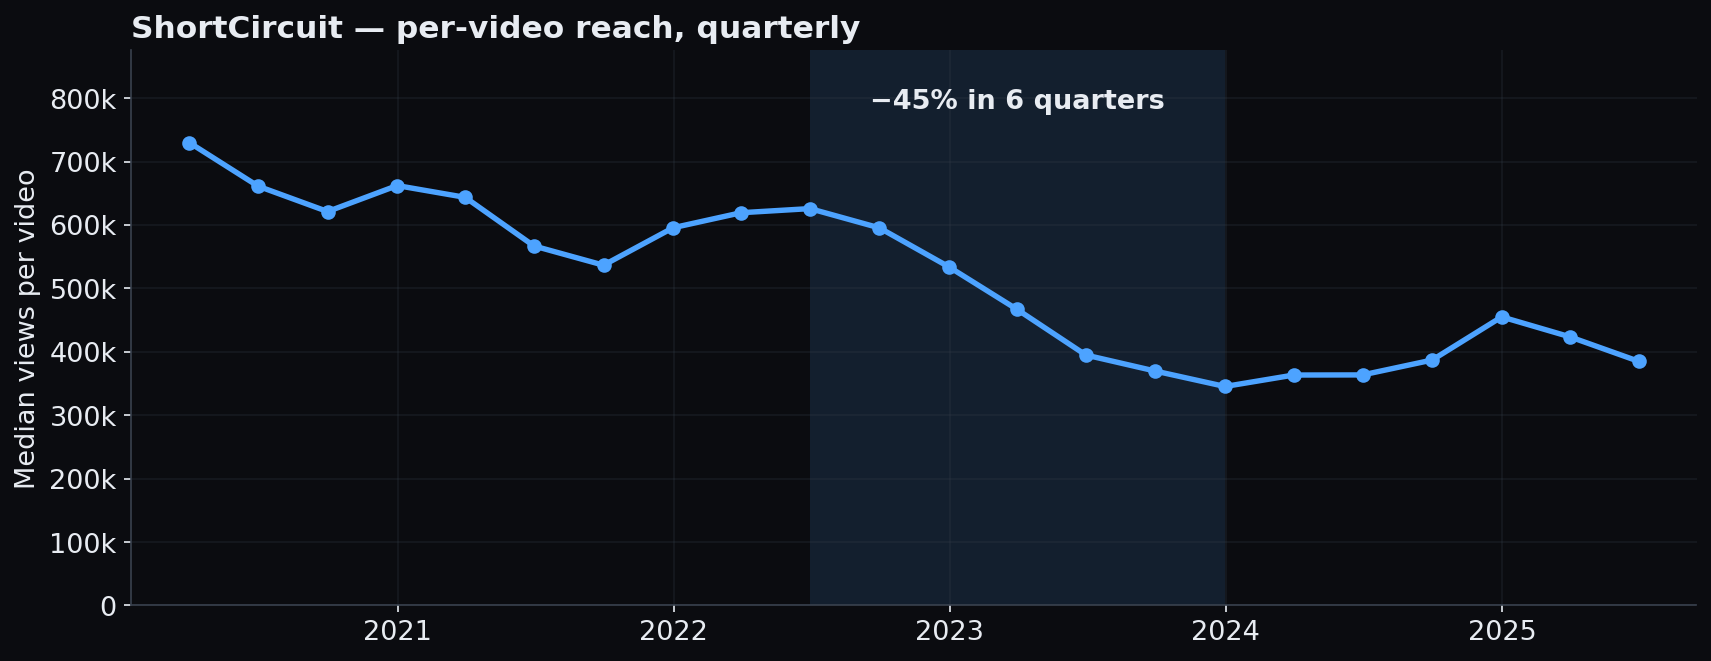

    reach_over_time: trimmed to 2025-06-30 (365d before the last upload quarter)


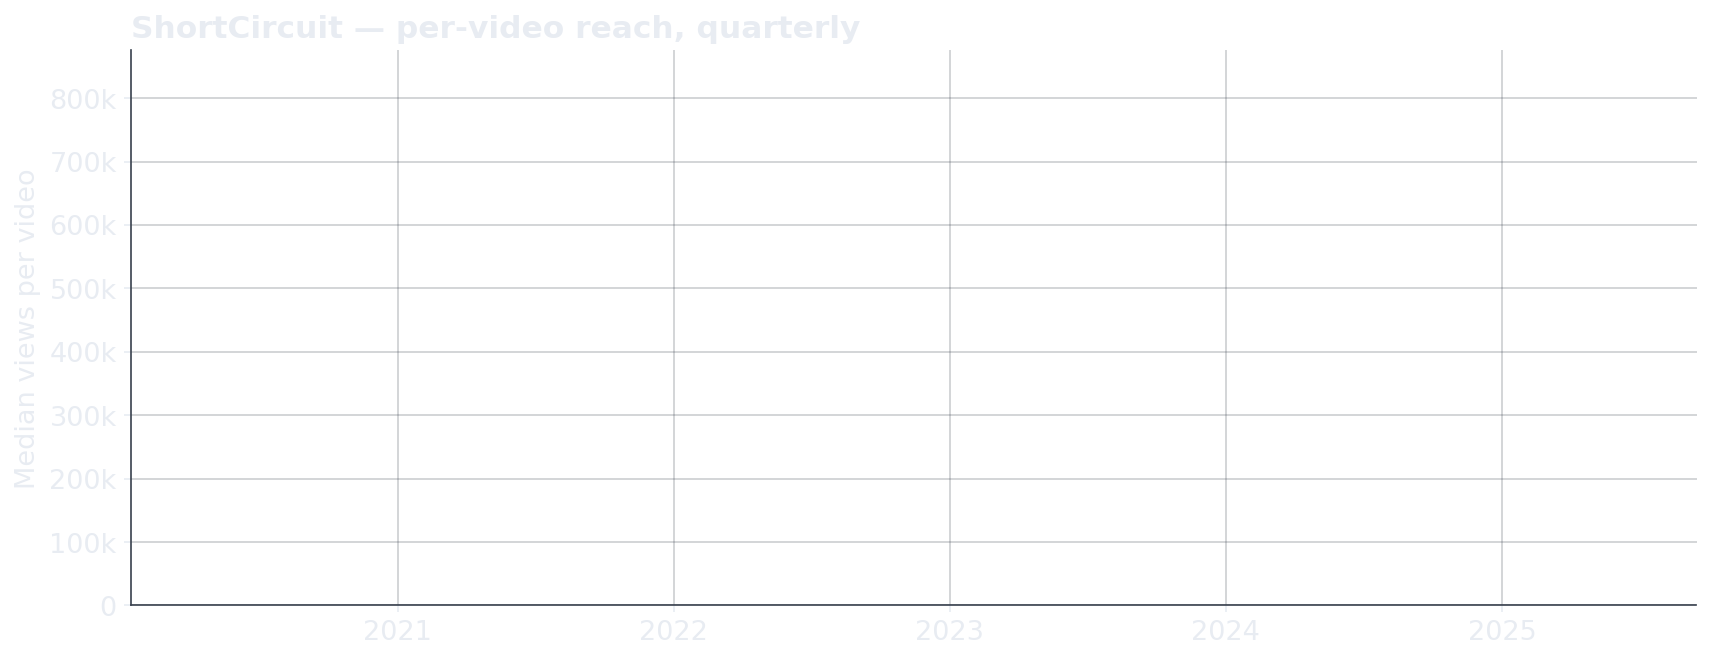

  reach_over_time            dark/reach_over_time.png  +  remotion/reach_over_time_plate.png & .json


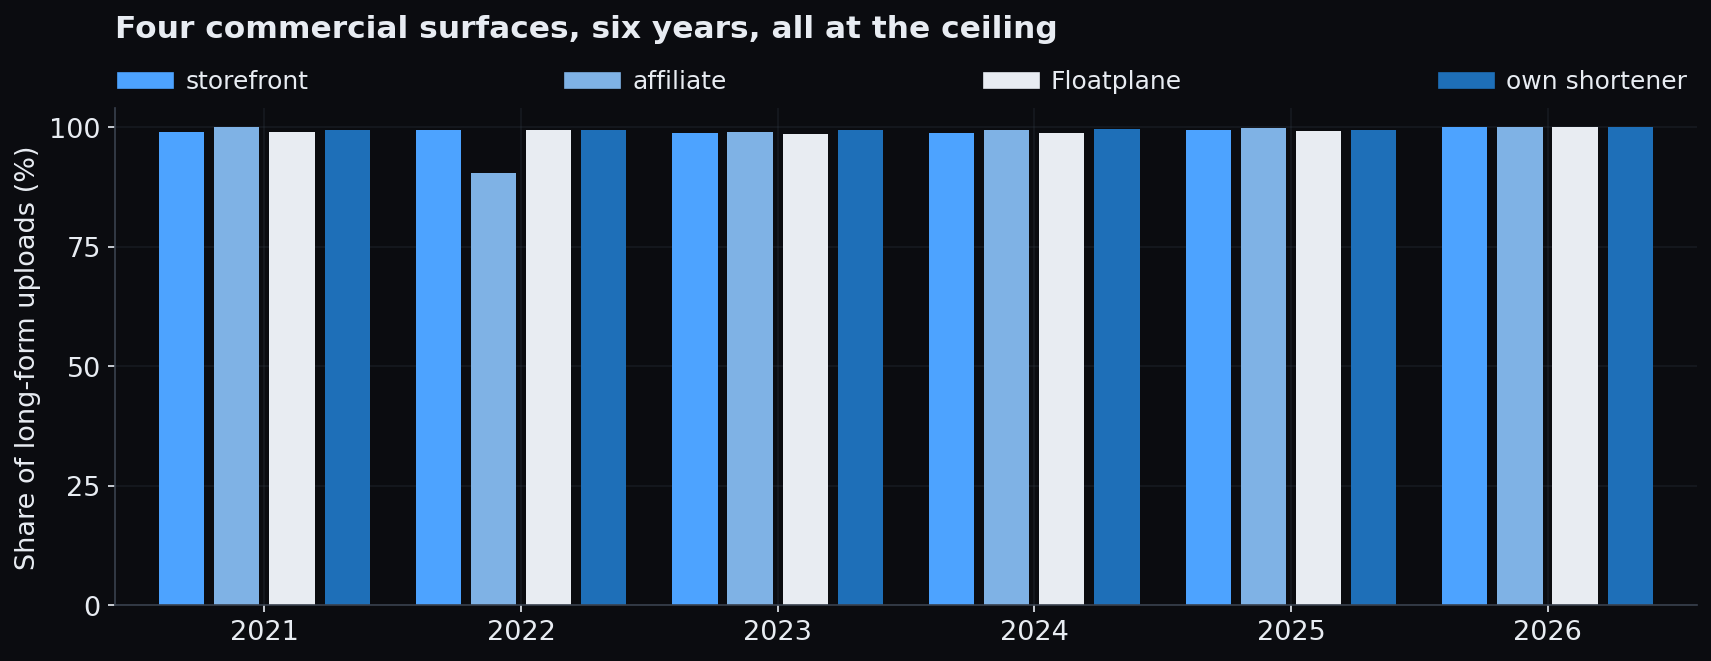

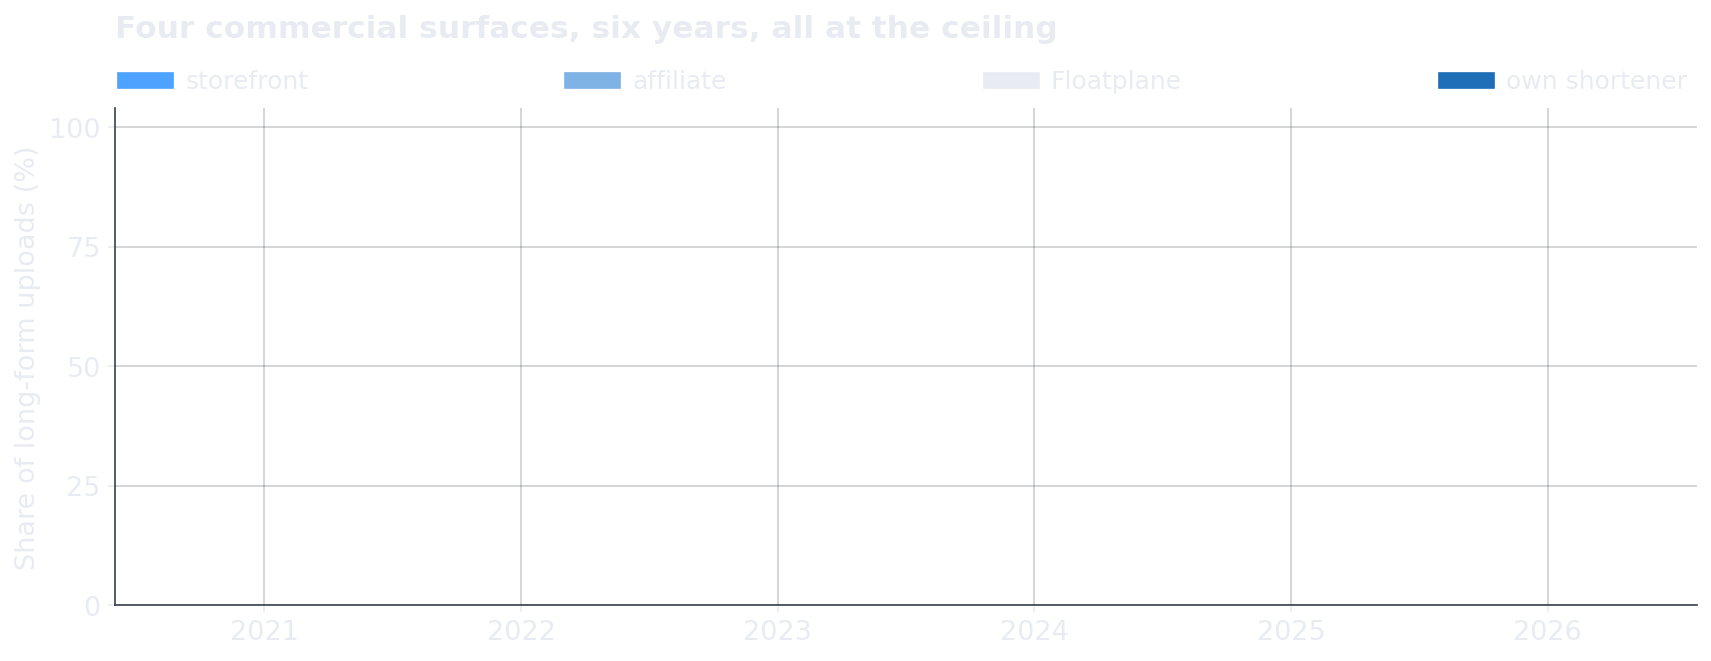

  commercial_surfaces        dark/commercial_surfaces.png  +  remotion/commercial_surfaces_plate.png & .json


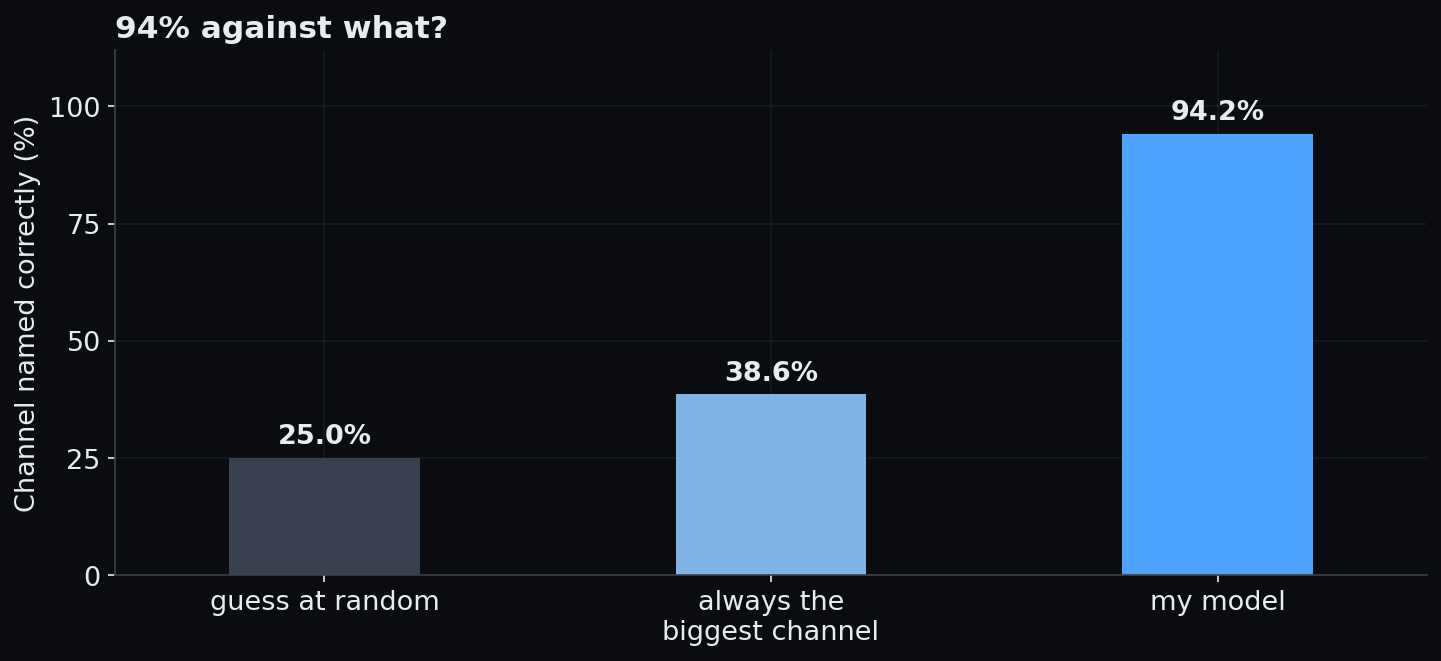

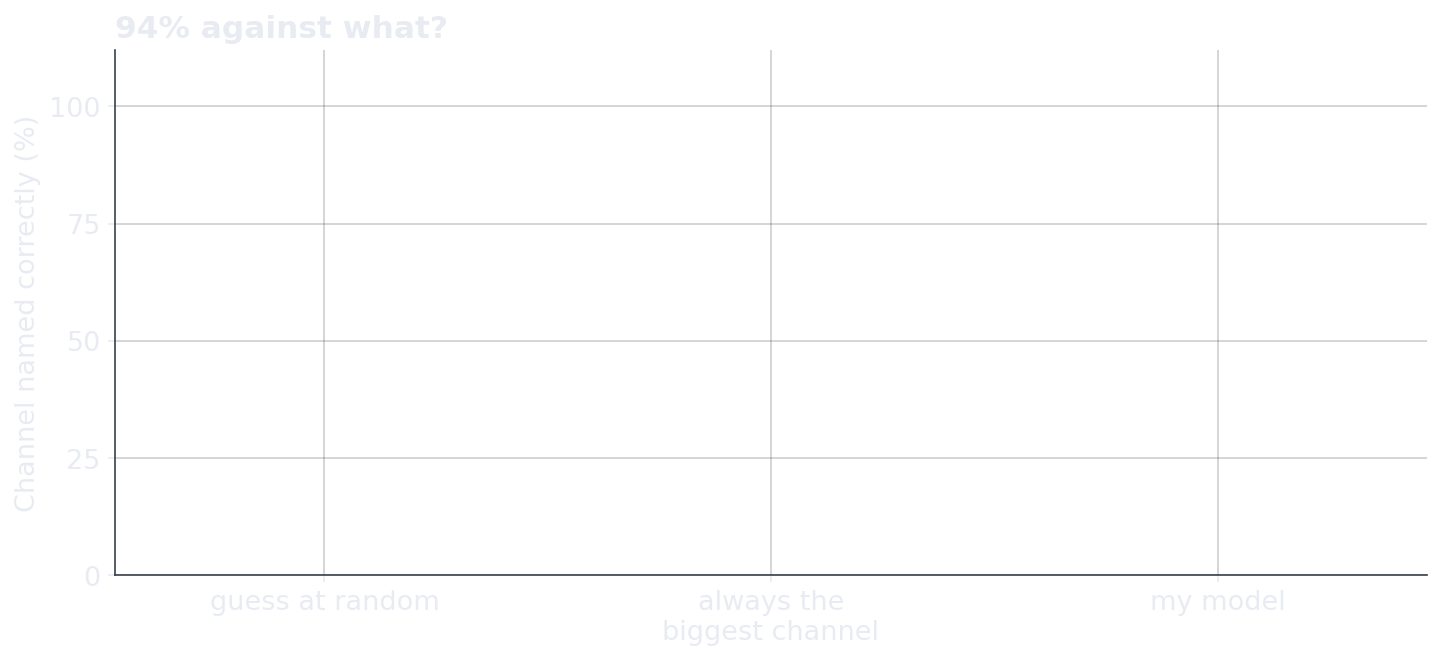

  positive_control           dark/positive_control.png  +  remotion/positive_control_plate.png & .json


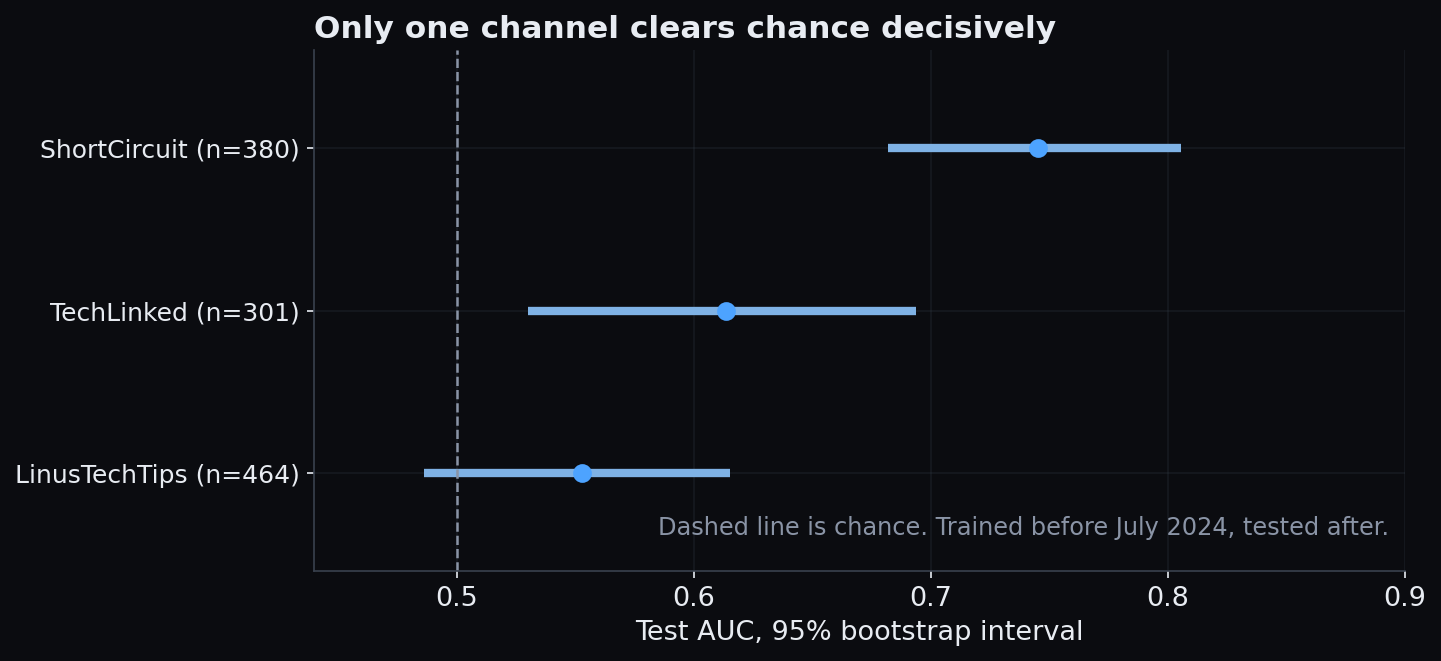

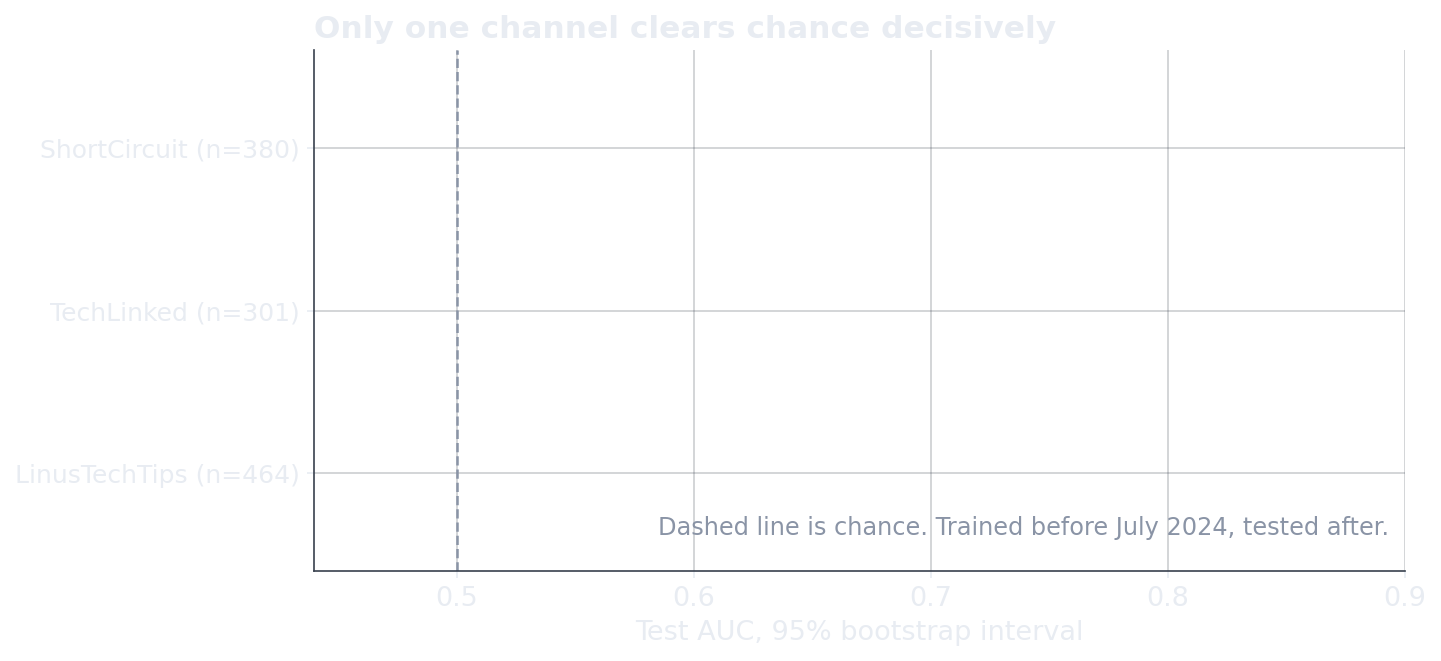

  content_model_right        dark/content_model_right.png  +  remotion/content_model_right_plate.png & .json


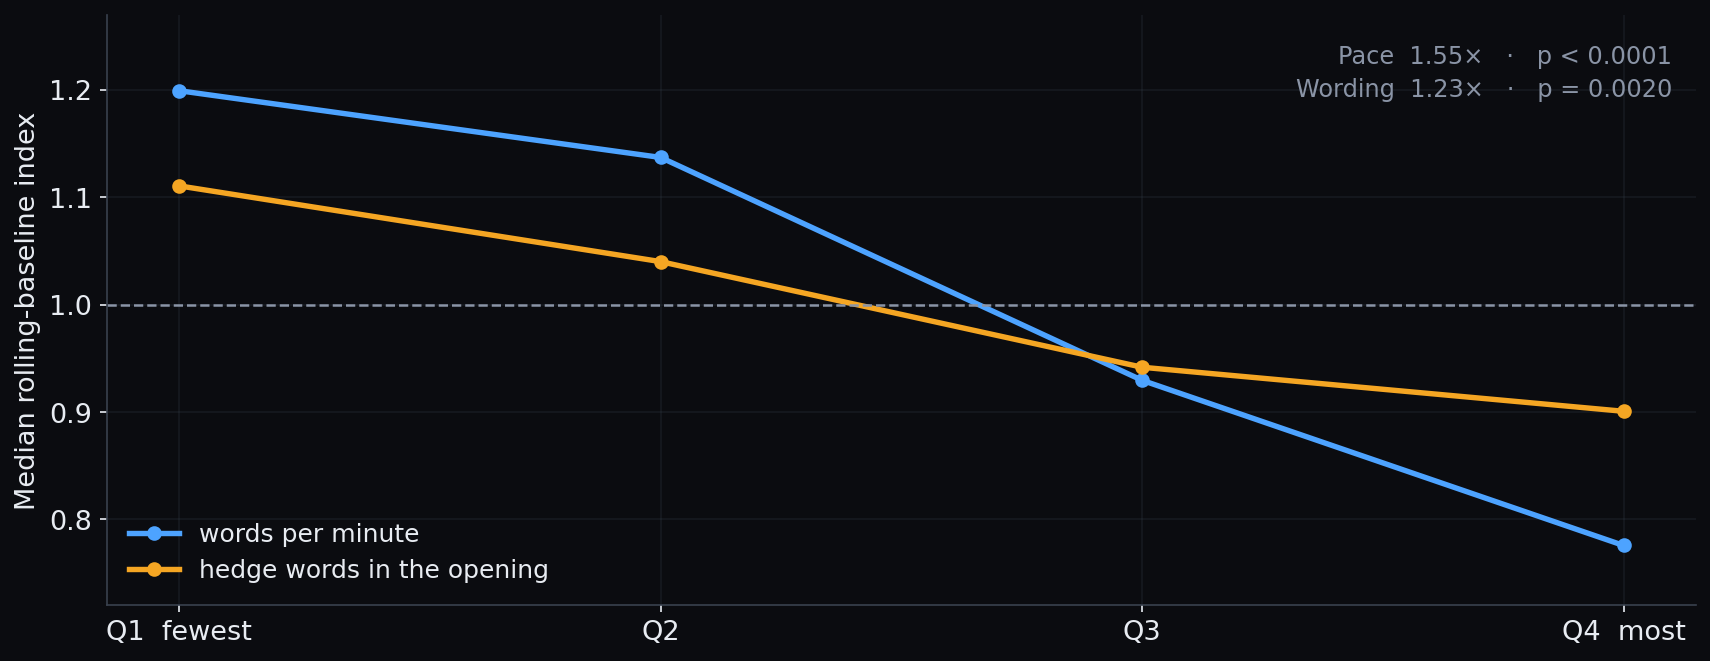

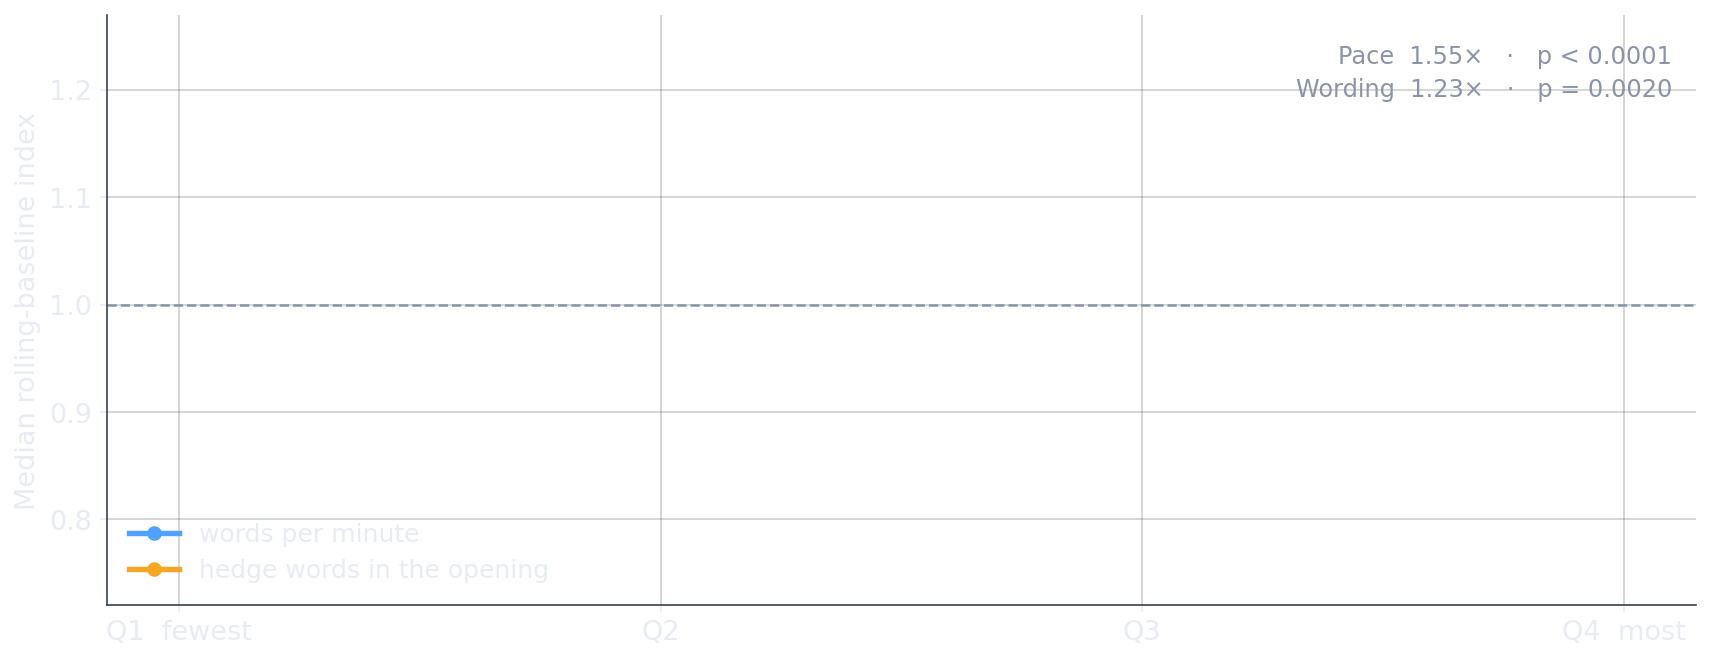

  pace_vs_wording            dark/pace_vs_wording.png  +  remotion/pace_vs_wording_plate.png & .json


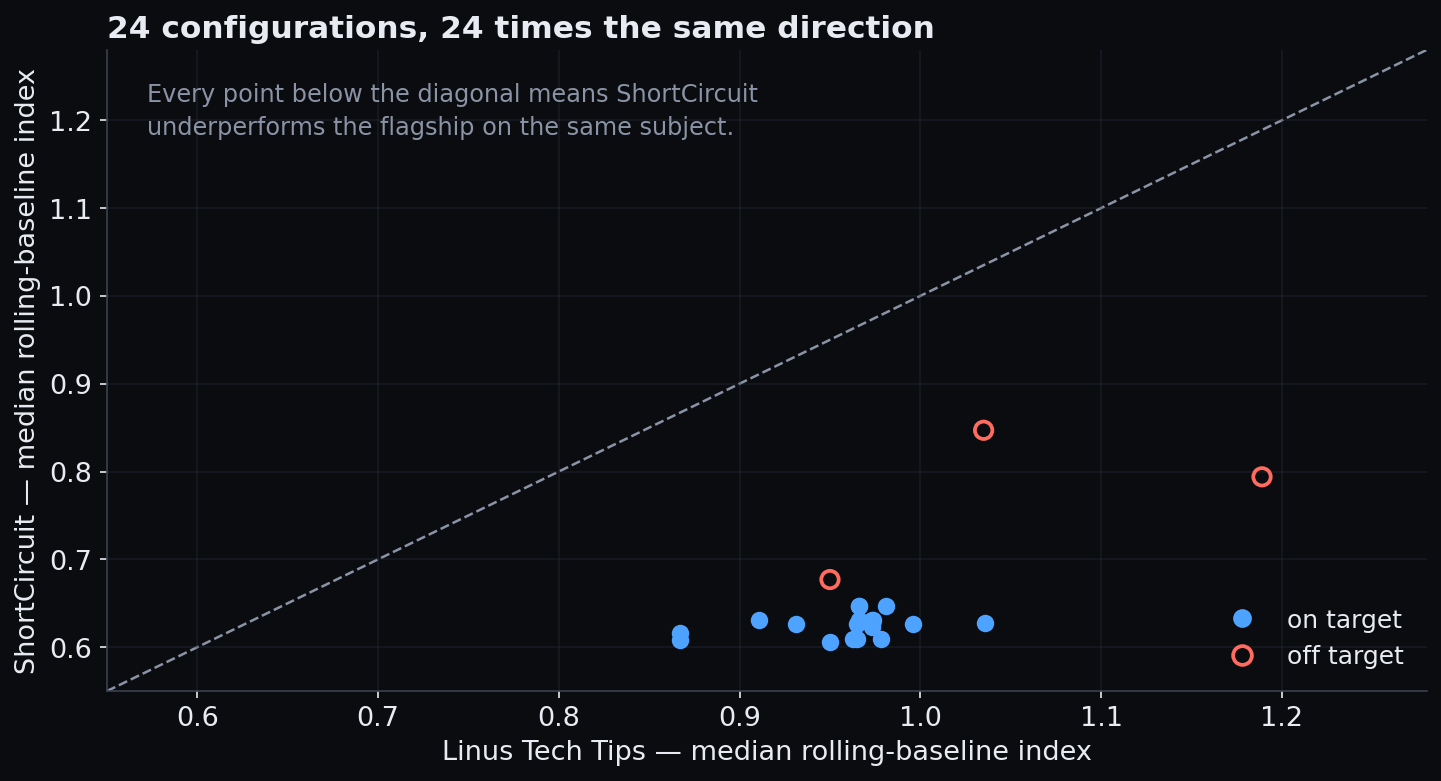

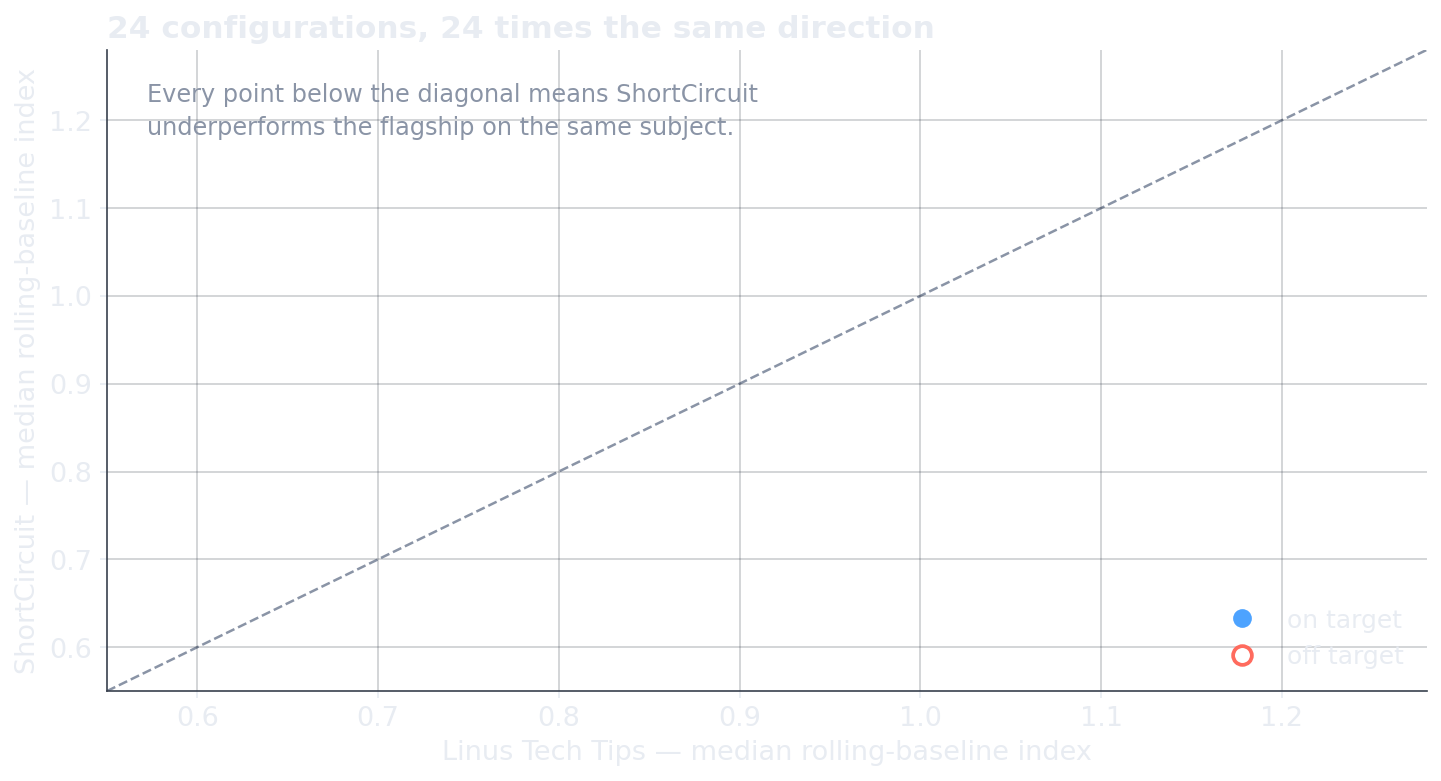

  stability                  dark/stability.png  +  remotion/stability_plate.png & .json


In [3]:
def draw(name, with_data, out_png, out_json=None):
    spec, d = CHARTS[name], load(name)
    # A chart built here rather than upstream (the bar chart) has no `axes` block yet:
    # its limits come from the spec and its geometry is written out below. Defaulting
    # instead of demanding the key keeps one renderer for both kinds of source.
    ax_meta = d.setdefault("axes", [{"xlim": [0, 1], "ylim": [0, 1],
                                     "xscale": "linear", "yscale": "linear"}])[0]

    # --- per-chart series surgery, all of it declared in the spec -----------------
    if spec.get("only"):
        d["series"] = [s for s in d["series"] if s["name"] in spec["only"]]
    for nm, col in spec.get("recolor", {}).items():
        for s in d["series"]:
            if s["name"] == nm:
                s["color"] = col
    if spec.get("trim_days"):
        cut = (max(np.datetime64(v) for s in d["series"] for v in s["x"])
               - np.timedelta64(spec["trim_days"], "D"))
        for s in d["series"]:
            keep = [i for i, v in enumerate(s["x"]) if np.datetime64(v) <= cut]
            for k in ("x", "y", "x_num"):
                if k in s:
                    s[k] = [s[k][i] for i in keep]
        print(f"    {name}: trimmed to {d['series'][0]['x'][-1]} "
              f"({spec['trim_days']}d before the last upload quarter)")
    dark_rc()
    fig, ax = plt.subplots(figsize=spec["size"], dpi=150)
    if not with_data:
        fig.patch.set_alpha(0); ax.patch.set_alpha(0)

    handles = []
    for si, s in enumerate(d["series"]):
        col, kind = s["color"], s.get("kind", "line")
        if kind == "line":
            x = s["x_num"] if spec.get("date_x") and "x_num" in s else s["x"]
            if with_data:
                ax.plot(x, s["y"], "o-", color=col, lw=2.6, ms=6)
            else:
                ax.plot(x, s["y"], alpha=0)          # sets the limits, draws nothing
            handles.append(Line2D([], [], color=col, lw=2.6, marker="o", ms=6, label=s["name"]))
        elif kind == "interval":
            y = s["y"]
            if with_data:
                ax.hlines(y, s["lo"], s["hi"], color=DIM, lw=4, zorder=2)
                ax.plot(s["point"], y, "o", color=col, ms=8, zorder=3)
            ax.plot([s["lo"], s["hi"]], [y, y], alpha=0)
        elif kind == "bar":
            # Width comes from the JSON, not from a guess here: the notebook that made
            # the data decided how four bars share a year, and Remotion reads the same
            # number. Three places computing a bar width independently is three places
            # to disagree.
            bw = d.get("bar_width", .2)
            if with_data:
                # 0.82 of the slot, so bars inside a group are separated and the groups
                # read as groups. Drawn at full width they merge into one block per year.
                b = ax.bar(s["x"], s["y"], width=bw * .82, color=col, zorder=2)
                if spec.get("bar_labels"):
                    ax.bar_label(b, fmt=spec.get("bar_label_fmt", "%.1f%%"), padding=4,
                                 fontsize=13, color=INK, fontweight="bold")
            elif spec.get("bar_labels"):
                # Same reasoning as the highlight label: the value has to arrive WITH its
                # bar, so it cannot be baked into the plate, and typing it in HTML would
                # put a second typeface inside one chart. Rendered here instead, one tight
                # transparent PNG per bar, in the font and size matplotlib would have used.
                # pad_inches=0 so the PNG's bottom edge IS the text's bottom edge and
                # Remotion can hang it off the bar top by the same 4pt bar_label padding.
                s["label_png"] = []
                for j, v in enumerate(s["y"]):
                    f2 = plt.figure(figsize=(2, .5), dpi=fig.dpi); f2.patch.set_alpha(0)
                    f2.text(.5, .5, spec.get("bar_label_fmt", "%.1f%%") % v,
                            ha="center", va="center",
                            fontsize=13, color=INK, weight="bold")
                    fn = f"{name}_label_{si}_{j}.png"
                    f2.savefig(REM/fn, transparent=True, bbox_inches="tight", pad_inches=0)
                    plt.close(f2)
                    s["label_png"].append(fn)
            handles.append(Line2D([], [], color=col, lw=8, label=s["name"]))
        elif kind == "scatter":
            filled = s.get("filled", True)
            if with_data:
                ax.scatter(s["x"], s["y"], s=70, zorder=3,
                           color=col if filled else "none",
                           edgecolor=col, linewidths=0 if filled else 1.8)
            handles.append(Line2D([], [], marker="o", ls="none", ms=9, label=s["name"],
                                  color=col if filled else "none",
                                  markerfacecolor=col if filled else "none",
                                  markeredgecolor=col, markeredgewidth=0 if filled else 1.8))

    if spec.get("bars"):
        xs = [v for s in d["series"] for v in s["x"]]
        # Padding is a fraction of a bar, not a multiple. At 3x the bars huddle in the
        # right half of a chart that is mostly empty; the first render did exactly that.
        pad = d.get("bar_width", .2) * (1.2 if len(d["series"]) > 3 else 0.9)
        ax.set_xlim(min(xs) - pad, max(xs) + pad)
        ax.set_ylim(*spec.get("ylim", (0, 112)))
        ax.grid(axis="y", alpha=.26, lw=.8); ax.grid(axis="x", visible=False)
    elif spec.get("autoscale"):
        # The JSON's limits describe the chart upstream drew. Once series are dropped or
        # trimmed they are wrong, and wrong in the flattering direction: a fall shown in
        # the top fifth of a frame sized for four channels barely reads.
        xs = [v for s in d["series"] for v in (s.get("x_num") or s["x"])]
        ys = [v for s in d["series"] for v in s["y"]]
        padx = (max(xs) - min(xs)) * .04
        ax.set_xlim(min(xs) - padx, max(xs) + padx)
        ax.set_ylim(0 if spec.get("y_from_zero") else min(ys) * .92, max(ys) * 1.20)
    else:
        ax.set_xlim(*ax_meta["xlim"]); ax.set_ylim(*ax_meta["ylim"])
    if spec.get("yscale", ax_meta["yscale"]) == "log": ax.set_yscale("log")
    if spec.get("ytick_thousands"):
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(
            lambda v, _: "0" if v == 0 else f"{v/1e3:,.0f}k"))
    if spec.get("invert_y"): ax.invert_yaxis()
    if spec.get("hline") is not None: ax.axhline(spec["hline"], color=SOFT, ls="--", lw=1.2)
    if spec.get("vline") is not None: ax.axvline(spec["vline"], color=SOFT, ls="--", lw=1.2)
    if spec.get("diagonal"):
        lo, hi = ax_meta["xlim"]; ax.plot([lo, hi], [lo, hi], ls="--", color=SOFT, lw=1.2, zorder=1)
    if spec.get("highlight"):
        h = decline_window(d["series"][0], **spec["highlight"])
        h["label_y"] = ax.get_ylim()[1] * .93
        d["highlight"] = h
        # Drawn only on the deck figure. The band is animated in Remotion — it wipes in
        # after the line lands — so for the plate it counts as a data mark and stays off,
        # and its geometry travels in the JSON instead.
        if with_data:
            ax.axvspan(h["x0"], h["x1"], color=ACCENT, alpha=.13, lw=0, zorder=0)
            ax.text((h["x0"] + h["x1"]) / 2, h["label_y"], h["label"], ha="center",
                    va="top", fontsize=13, color=INK, weight="bold")
        else:
            # The band's label has to fade in with the band, so it cannot be baked into
            # the plate — and setting it in HTML would put a second typeface inside one
            # chart, which the plate contract forbids for exactly this reason. So it is
            # rendered here as its own tight transparent PNG, in the same font at the same
            # size, for Remotion to position from `highlight` and fade.
            f2 = plt.figure(figsize=(6, .6), dpi=fig.dpi); f2.patch.set_alpha(0)
            f2.text(.5, .5, h["label"], ha="center", va="center",
                    fontsize=13, color=INK, weight="bold")
            f2.savefig(REM/f"{name}_label.png", transparent=True,
                       bbox_inches="tight", pad_inches=0.03)
            plt.close(f2)
            h["label_png"] = f"{name}_label.png"
    if spec.get("shade"):
        a, b, lab = spec["shade"]
        xa, xb = mdates.date2num(np.datetime64(a)), mdates.date2num(np.datetime64(b))
        ax.axvspan(xa, xb, color=INK, alpha=.05)
        ax.text((xa+xb)/2, ax.get_ylim()[0]*1.35, lab, ha="center", fontsize=11, color=SOFT)
    if spec.get("date_x"):
        ax.xaxis.set_major_locator(mdates.YearLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    if spec.get("xticks_year"):
        yrs = sorted({int(round(v)) for s in d["series"] for v in s["year"]}) \
              if "year" in d["series"][0] else []
        ax.set_xticks(yrs); ax.set_xticklabels([str(y) for y in yrs])
    if spec.get("xticks_int"):
        ax.set_xticks(sorted({int(v) for s in d["series"] for v in s["x"]}))
    if spec.get("xtick_labels"):
        # For a bar chart the tick positions are the bars' own x values, not 0..n-1:
        # a single-bar-per-series chart has one x per series, and assuming an index
        # would silently put the labels under the wrong bars.
        xs = ([v for s_ in d["series"] for v in s_["x"]] if spec.get("bars")
              else list(np.arange(len(spec["xtick_labels"]))))
        ax.set_xticks(sorted(xs)); ax.set_xticklabels(spec["xtick_labels"])
    if spec.get("yticks"): ax.set_yticks(spec["yticks"])
    if any(s.get("kind") == "interval" for s in d["series"]):
        ax.set_yticks([s["y"] for s in d["series"]])
        ax.set_yticklabels([s.get("label", s["name"]) for s in d["series"]], fontsize=12)

    ax.set_title(spec["title"], loc="left", weight="bold", color=INK, fontsize=15,
                 pad=34 if spec.get("legend") == "above" else 6)
    if spec.get("xlabel"): ax.set_xlabel(spec["xlabel"])
    if spec.get("ylabel"): ax.set_ylabel(spec["ylabel"])
    if spec.get("note"):
        hx, hy = spec["note_xy"]
        ax.text(hx, hy, spec["note"], transform=ax.transAxes,
                ha=spec.get("note_ha", "right"),
                va="top" if hy > .5 else "bottom", fontsize=11.5, color=SOFT, linespacing=1.5)
    if spec.get("legend") and handles:
        if spec["legend"] == "above":
            leg = ax.legend(handles=handles, frameon=False, fontsize=12,
                            loc="lower left", bbox_to_anchor=(0, 1.01, 1, .12),
                            mode="expand", ncol=spec.get("legend_cols", 1),
                            borderaxespad=0, handlelength=1.6)
        else:
            leg = ax.legend(handles=handles, frameon=False, fontsize=12, loc=spec["legend"],
                            ncol=spec.get("legend_cols", 1))
        for t in leg.get_texts(): t.set_color(INK)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=.26, lw=.8)
    plt.tight_layout()
    fig.savefig(out_png, bbox_inches=None, transparent=not with_data)

    if out_json:
        w, h = fig.get_size_inches()*fig.dpi; pos = ax.get_position()
        d["figure_px"] = {"w": w, "h": h}; d["dpi"] = fig.dpi
        # bar_label's padding, converted once here rather than in the component: 4 points
        # at this figure's dpi. Remotion hangs each label PNG this far above its bar top.
        if spec.get("bar_labels"):
            d["label_pad_px"] = 4 * fig.dpi / 72
        d["axes"][0]["px"] = {"x": pos.x0*w, "y": (1-pos.y1)*h,
                              "w": pos.width*w, "h": pos.height*h}
        d["axes"][0]["xlim"] = list(ax.get_xlim()); d["axes"][0]["ylim"] = list(ax.get_ylim())
        # The scale has to be written too, not inherited. reach_over_time is linear here
        # and logarithmic upstream, and a component that reads the stale "log" would place
        # every point of the line somewhere plausible and wrong.
        d["axes"][0]["yscale"] = spec.get("yscale", ax_meta["yscale"])
        json.dump(d, open(out_json, "w"), indent=1)
    plt.show(); plt.close(fig); plt.rcParams.update(plt.rcParamsDefault)

for name in CHARTS:
    draw(name, True,  DARK/f"{name}.png")
    draw(name, False, REM/f"{name}_plate.png", REM/f"{name}.json")
    print(f"  {name:26s} dark/{name}.png  +  remotion/{name}_plate.png & .json")

> **What to check on these.**
>
> The plate and the deck figure are the same drawing with the marks switched off, so if a point looks
> misplaced in the animation the plate is not the suspect — the mapping is.
>
> The geometry in each JSON is rewritten on this pass, because the dark figures are a different size
> from the light originals. Any Remotion component built against the earlier geometry must be
> re-checked: the `px` box moved.